In [40]:
import autoroot
import matplotlib.pyplot as plt

import numpy as np
from src.utils.tools import get_rho_lstsq
from src.data.lf.lf_datamodule import LF
L = 128
d = 3


lf = LF(
    data_dir="",
    N=200,
    T=L,
    D=1,
    rho_name="exponential",
    rho_param={"alpha": 0.8},
    input_generator="randn",
    # processing=["smooth_noise"]
)


def reshape_and_pad_batch(arr, d):
    B, L, C = arr.shape  # C should be 1
    assert C == 1, "Input must have shape (Batch, L, 1)"

    # Calculate new padded length for L dimension
    padded_L = int(np.ceil(L / d)) * d

    if padded_L > L:
        pad_width = padded_L - L
        # Pad along axis=1 (time dimension)
        pad_shape = ((0, 0), (0, pad_width), (0, 0))  # Only pad L dimension
        arr = np.pad(arr, pad_shape, mode='constant', constant_values=0)

    # Reshape: (B, padded_L, 1) → (B, padded_L // d, d)
    arr = arr.reshape(B, -1, d)

    return arr
    
    return reshaped


In [41]:
data = lf.dataset_construction()[0]
x, y = data[:][0].numpy(), data[:][1].numpy()

./src/utils/tools.py:34: FutureWarning: Beginning in SciPy 1.17, multidimensional input will be treated as a batch, not `ravel`ed. To preserve the existing behavior and silence this warning, `ravel` arguments before passing them to `toeplitz`.
  toeplitz_matrix = toeplitz(x_flat[..., d])[:, :path_length]  # (data_num * path_length, path_length)


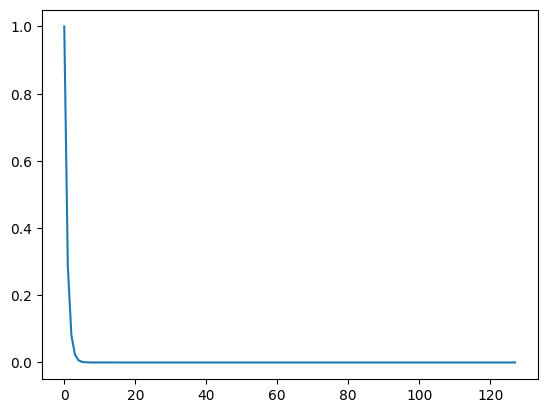

In [42]:
plt.plot(get_rho_lstsq(x,y))

In [43]:
x_reshape,y_reshape = reshape_and_pad_batch(x,d),reshape_and_pad_batch(y,d)

./src/utils/tools.py:34: FutureWarning: Beginning in SciPy 1.17, multidimensional input will be treated as a batch, not `ravel`ed. To preserve the existing behavior and silence this warning, `ravel` arguments before passing them to `toeplitz`.
  toeplitz_matrix = toeplitz(x_flat[..., d])[:, :path_length]  # (data_num * path_length, path_length)


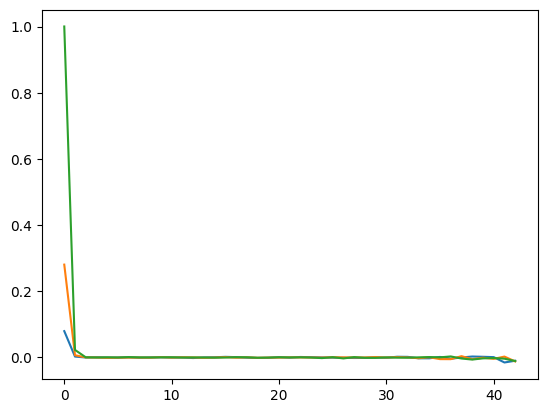

In [46]:
plt.plot(get_rho_lstsq(x_reshape,y_reshape,ydim=2))